In [56]:
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [57]:
%pip install -r ../requirements.txt
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [58]:
%pip install openpyxl
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer

file_path = '../Survey-Survey-cleaned.csv.xlsx'
try:
    df = pd.read_excel(file_path)
except Exception:
    df = pd.read_csv(file_path)

print("Columns in dataset:")
for idx, col in enumerate(df.columns):
    print(f"{idx}: {col}")

Note: you may need to restart the kernel to use updated packages.
Columns in dataset:
0: I Agree to participate in the research project under the conditions described above
1: The name of your institution
2: The name of your program of study
3: Your current class level is
4: Your gender
5: Your current age
6: Living with family?
7: Are you happy with your academic  Condition?
8: Your CGPA
9: Are you addicted to any drugs?
10: Are you in a relationship?
11: Did you have a recent breakup?
12: How often do you conflict with your friend?
13: Do you have financial problem in your family?
14: Violence in family?
15: Have you ever been bullied
16: Have you ever been sexually harassed or abused?
17: How many hours do you spend on social media?
18: 1. I found it hard to wind down
19: 2. I tended to over-react to situations
20: 3 .I felt that I was using a lot of nervous energy
21: 4.  I found myself getting agitated
22: 5.  I found it difficult to relax
23: 6.  I was intolerant of anything that

In [59]:
# Data cleaning + organising

tipi_rename_map = {
    '1. _____ Extraverted, enthusiastic.': 'TIPI_1',
    '2. _____ Critical, quarrelsome.': 'TIPI_2',
    '3. _____ Dependable, self-disciplined.': 'TIPI_3',
    '4. _____ Anxious, easily upset.': 'TIPI_4',
    '5. _____ Open to new experiences, complex.': 'TIPI_5',
    '6. _____ Reserved, quiet.': 'TIPI_6',
    '7. _____ Sympathetic, warm.': 'TIPI_7',
    '8. _____ Disorganized, careless.': 'TIPI_8',
    '9. _____ Calm, emotionally stable': 'TIPI_9',
    '10. _____ Conventional, uncreative.': 'TIPI_10'
}

dass_rename_map = {
    '1. I found it hard to wind down': 'DASS_1',
    '2. I tended to over-react to situations': 'DASS_2',
    '3 .I felt that I was using a lot of nervous energy': 'DASS_3',
    '4.  I found myself getting agitated': 'DASS_4',
    '5.  I found it difficult to relax': 'DASS_5',
    '6.  I was intolerant of anything that kept me from getting on with what I was doing': 'DASS_6',
    '7.  I felt that I was rather touchy': 'DASS_7'
}

df = df.rename(columns=tipi_rename_map)
df = df.rename(columns=dass_rename_map)

tipi_cols = [f'TIPI_{i}' for i in range(1, 11)]
stress_cols = [f'DASS_{i}' for i in range(1, 8)]

def clean_text(text):
    if pd.isna(text): return 'Unknown'
    return str(text).strip().lower()

program_standard_map = {
    'cse': 'Computer Science & Engineering', 'computer science': 'Computer Science', 'cs': 'Computer Science',
    'eee': 'Electrical & Electronic Engineering', 'bba': 'Business Administration', 'physics': 'Physics',
    'law': 'Law', 'llb': 'Law', 'english': 'English', 'civil': 'Civil Engineering',
    'mechanical': 'Mechanical Engineering', 'textile': 'Textile Engineering', 'chemistry': 'Chemistry',
    'botany': 'Botany', 'zoology': 'Zoology', 'pharmacy': 'Pharmacy', 'history': 'History',
    'sociology': 'Sociology', 'economics': 'Economics'
}

institution_standard_map = {
    'edu': 'East Delta University', 'east delta': 'East Delta University',
    'chittagong university': 'University of Chittagong', 'cu': 'University of Chittagong',
    'iiuc': 'International Islamic University Chittagong', 'cvasu': 'CVASU', 'bgc': 'BGC Trust University',
    'ciu': 'Chittagong Independent University', 'cuet': 'CUET', 'dhaka university': 'University of Dhaka',
    'du': 'University of Dhaka', 'aiub': 'AIUB', 'buet': 'BUET'
}

def map_program(val):
    clean = clean_text(val)
    for keyword, standard in program_standard_map.items():
        if keyword in clean: return standard
    return 'Other/General'

def map_institution(val):
    clean = clean_text(val)
    for keyword, standard in institution_standard_map.items():
        if keyword in clean: return standard
    return 'Other/General'

df['Program_Cleaned'] = df['The name of your program of study'].apply(map_program)
df['Institution_Cleaned'] = df['The name of your institution'].apply(map_institution)

class_level_mapping = {
    "Freshman (Undergrad)": 0, "Sophomore (Undergrad)": 1,
    "Junior (Undergrad)": 2, "Senior (Undergrad)": 3, "Graduate student": 4
}
df['class_level_num'] = df['Your current class level is'].map(class_level_mapping)
df['class_level_num'] = df['class_level_num'].fillna(df['class_level_num'].median())
print("Data loaded and initial features cleaned successfully.")

Data loaded and initial features cleaned successfully.


In [60]:
#LIFESTYLE & DEMOGRAPHIC FEATURES

def norm(val):
    """Lower-case and remove spaces so 'Yes ', 'yes' and 'YES' all match."""
    if pd.isna(val):
        return np.nan
    return str(val).strip().lower().replace(' ', '')

binary_map = {'no': 0, 'yes': 1}

lifestyle_specs = {
    'Living with family?':                               ('family_num',           binary_map),
    'Are you happy with your academic  Condition?':      ('academic_happy_num',   binary_map),
    'Are you addicted to any drugs?':                    ('drugs_num',            binary_map),
    'Are you in a relationship?':                        ('relationship_num',     binary_map),
    'Did you have a recent breakup?':                    ('breakup_num',          binary_map),
    'Do you have financial problem in your family?':     ('finance_num',          binary_map),
    'Have you ever been bullied':                        ('bullied_num',          binary_map),
    'Have you ever been sexually harassed or abused?':   ('harassed_num',         binary_map),
    'Your current age':                                  ('age_num',              {'<20': 0, '20-25': 1, '21-25': 1, '>25': 2}),
    'Your CGPA':                                         ('cgpa_num',             {'<3.00': 0, '3.01-3.50': 1, '>3.50': 2}),
    'How often do you conflict with your friend?':       ('conflict_num',         {'neveroccurs': 0, 'never': 0, 'sometimes': 1, 'mostofthetime': 2}),
    'Violence in family?':                               ('violence_num',         {'never': 0, 'rarely': 1, 'often': 2, 'mostofthetime': 3}),
    'How many hours do you spend on social media?':      ('social_media_num',     {'<1hours': 0, '<1hour': 0, '1-3hours': 1, '1-3hour': 1, '>3hours': 2, '>3hour': 2}),
}

for raw_col, (num_col, mapping) in lifestyle_specs.items():
    normed = df[raw_col].apply(norm)
    df[num_col] = normed.map(mapping)

    unmapped = df.loc[normed.notna() & df[num_col].isna(), raw_col].unique()
    if len(unmapped) > 0:
        print(f"WARNING - '{raw_col}' has values not in the mapping: {list(unmapped)}")

    df[num_col] = df[num_col].fillna(df[num_col].median())

lifestyle_raw_cols = list(lifestyle_specs.keys())
lifestyle_num_cols = [num_col for num_col, _ in lifestyle_specs.values()]

print("\nEncoded lifestyle features (check the value counts look sensible):")
for raw_col, (num_col, _) in lifestyle_specs.items():
    print(f"\n{num_col}  <-  {raw_col}")
    print(df[num_col].value_counts().sort_index().to_string())


WARNING - 'Have you ever been sexually harassed or abused?' has values not in the mapping: ['Maybe']

Encoded lifestyle features (check the value counts look sensible):

family_num  <-  Living with family?
family_num
0    154
1    417

academic_happy_num  <-  Are you happy with your academic  Condition?
academic_happy_num
0    324
1    247

drugs_num  <-  Are you addicted to any drugs?
drugs_num
0    519
1     52

relationship_num  <-  Are you in a relationship?
relationship_num
0    396
1    175

breakup_num  <-  Did you have a recent breakup?
breakup_num
0    448
1    123

finance_num  <-  Do you have financial problem in your family?
finance_num
0    291
1    280

bullied_num  <-  Have you ever been bullied
bullied_num
0    226
1    345

harassed_num  <-  Have you ever been sexually harassed or abused?
harassed_num
0.0    409
1.0    162

age_num  <-  Your current age
age_num
0     36
1    460
2     75

cgpa_num  <-  Your CGPA
cgpa_num
0    126
1    287
2    158

conflict_num  <-  Ho

In [61]:
#KNN IMPUTATION
raw_with_zeros = df[tipi_cols].apply(pd.to_numeric, errors='coerce').copy()
raw_tipi = raw_with_zeros.replace(0, np.nan)

imputer = KNNImputer(n_neighbors=5)
imputed_tipi_arr = imputer.fit_transform(raw_tipi)
imputed_tipi_df = pd.DataFrame(imputed_tipi_arr, columns=tipi_cols, index=df.index).round().astype(int).clip(1, 7)

df[tipi_cols] = imputed_tipi_df

for col in stress_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col] = df[col].fillna(df[col].median())

df['Stress_Score'] = df[stress_cols].sum(axis=1)

#Big Five traits scoring
df['Extraversion'] = df['TIPI_1'] + (8 - df['TIPI_6'])
df['Agreeableness'] = (8 - df['TIPI_2']) + df['TIPI_7']
df['Conscientiousness'] = df['TIPI_3'] + (8 - df['TIPI_8'])
df['Emotional_Stability'] = (8 - df['TIPI_4']) + df['TIPI_9']
df['Openness'] = df['TIPI_5'] + (8 - df['TIPI_10'])

big_five_cols = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Emotional_Stability', 'Openness']

#DASS-21 scaling
df['DASS_Stress_Scaled'] = df['Stress_Score'] * 2
def get_severity_category(score):
    if score <= 14: return 'Normal'
    elif score <= 18: return 'Mild'
    elif score <= 25: return 'Moderate'
    elif score <= 33: return 'Severe'
    else: return 'Extremely Severe'

df['Stress_Severity'] = df['DASS_Stress_Scaled'].apply(get_severity_category)
category_order = ['Normal', 'Mild', 'Moderate', 'Severe', 'Extremely Severe']
df['Stress_Severity'] = pd.Categorical(df['Stress_Severity'], categories=category_order, ordered=True)
print("Traits calculated and reverse-coded successfully.")

Traits calculated and reverse-coded successfully.


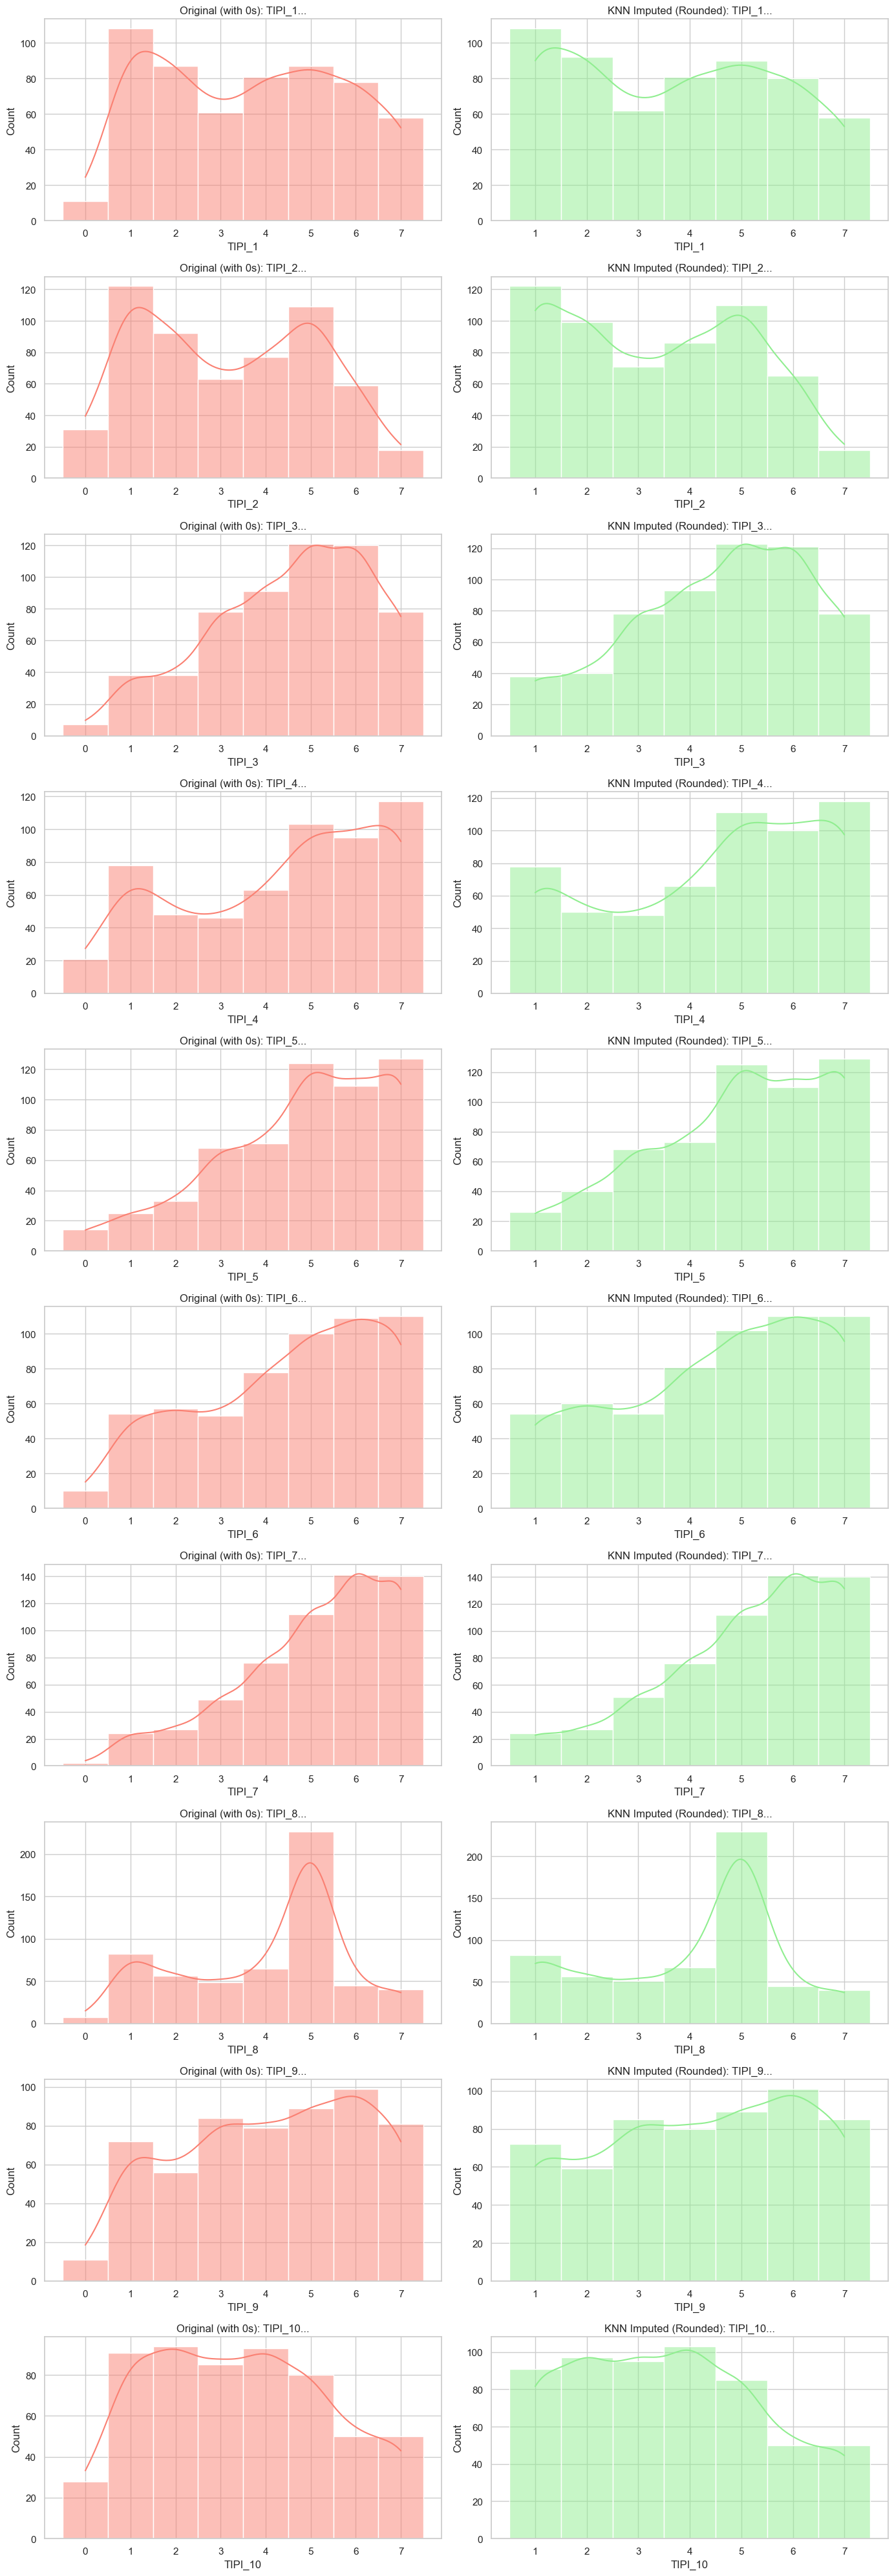

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer

#TIPI DISTRIBUTION COMPARISONS

cols_to_plot = [col for col in tipi_cols if (raw_with_zeros[col] == 0).any() or raw_with_zeros[col].isna().any()]

if len(cols_to_plot) == 0:
    raise ValueError('No 0s or missing values found in the raw TIPI columns - nothing to compare.')

# Plot the comparison
fig, axes = plt.subplots(len(cols_to_plot), 2, figsize=(14, 4 * len(cols_to_plot)))
if len(cols_to_plot) == 1:
    axes = np.expand_dims(axes, axis=0)

for idx, col in enumerate(cols_to_plot):
    # 1. Plot original with 0s
    sns.histplot(raw_with_zeros[col], kde=True, ax=axes[idx, 0], color='salmon', bins=np.arange(-0.5, 8.5, 1))
    axes[idx, 0].set_title(f"Original (with 0s): {col[:35]}...")
    axes[idx, 0].set_xticks(range(8))

    # 2. Plot after KNN Imputation
    sns.histplot(imputed_tipi_df[col], kde=True, ax=axes[idx, 1], color='lightgreen', bins=np.arange(0.5, 8.5, 1))
    axes[idx, 1].set_title(f"KNN Imputed (Rounded): {col[:35]}...")
    axes[idx, 1].set_xticks(range(1, 8))

plt.tight_layout()
plt.show()

=== NUMERICAL REGRESSION METRICS ===

Linear Regression   -> Model 1 (Baseline) | MSE: 29.444 | RMSE: 5.426 | MAE: 4.622 | R²: 0.144
                      Model 2 (With TIPI) | MSE: 28.490 | RMSE: 5.338 | MAE: 4.387 | R²: 0.172

K-Nearest Neighbors -> Model 1 (Baseline) | MSE: 31.965 | RMSE: 5.654 | MAE: 4.883 | R²: 0.071
                      Model 2 (With TIPI) | MSE: 29.860 | RMSE: 5.464 | MAE: 4.704 | R²: 0.132

Decision Tree       -> Model 1 (Baseline) | MSE: 31.252 | RMSE: 5.590 | MAE: 4.757 | R²: 0.092
                      Model 2 (With TIPI) | MSE: 39.839 | RMSE: 6.312 | MAE: 5.149 | R²: -0.158

Random Forest       -> Model 1 (Baseline) | MSE: 31.909 | RMSE: 5.649 | MAE: 4.876 | R²: 0.073
                      Model 2 (With TIPI) | MSE: 29.019 | RMSE: 5.387 | MAE: 4.528 | R²: 0.157


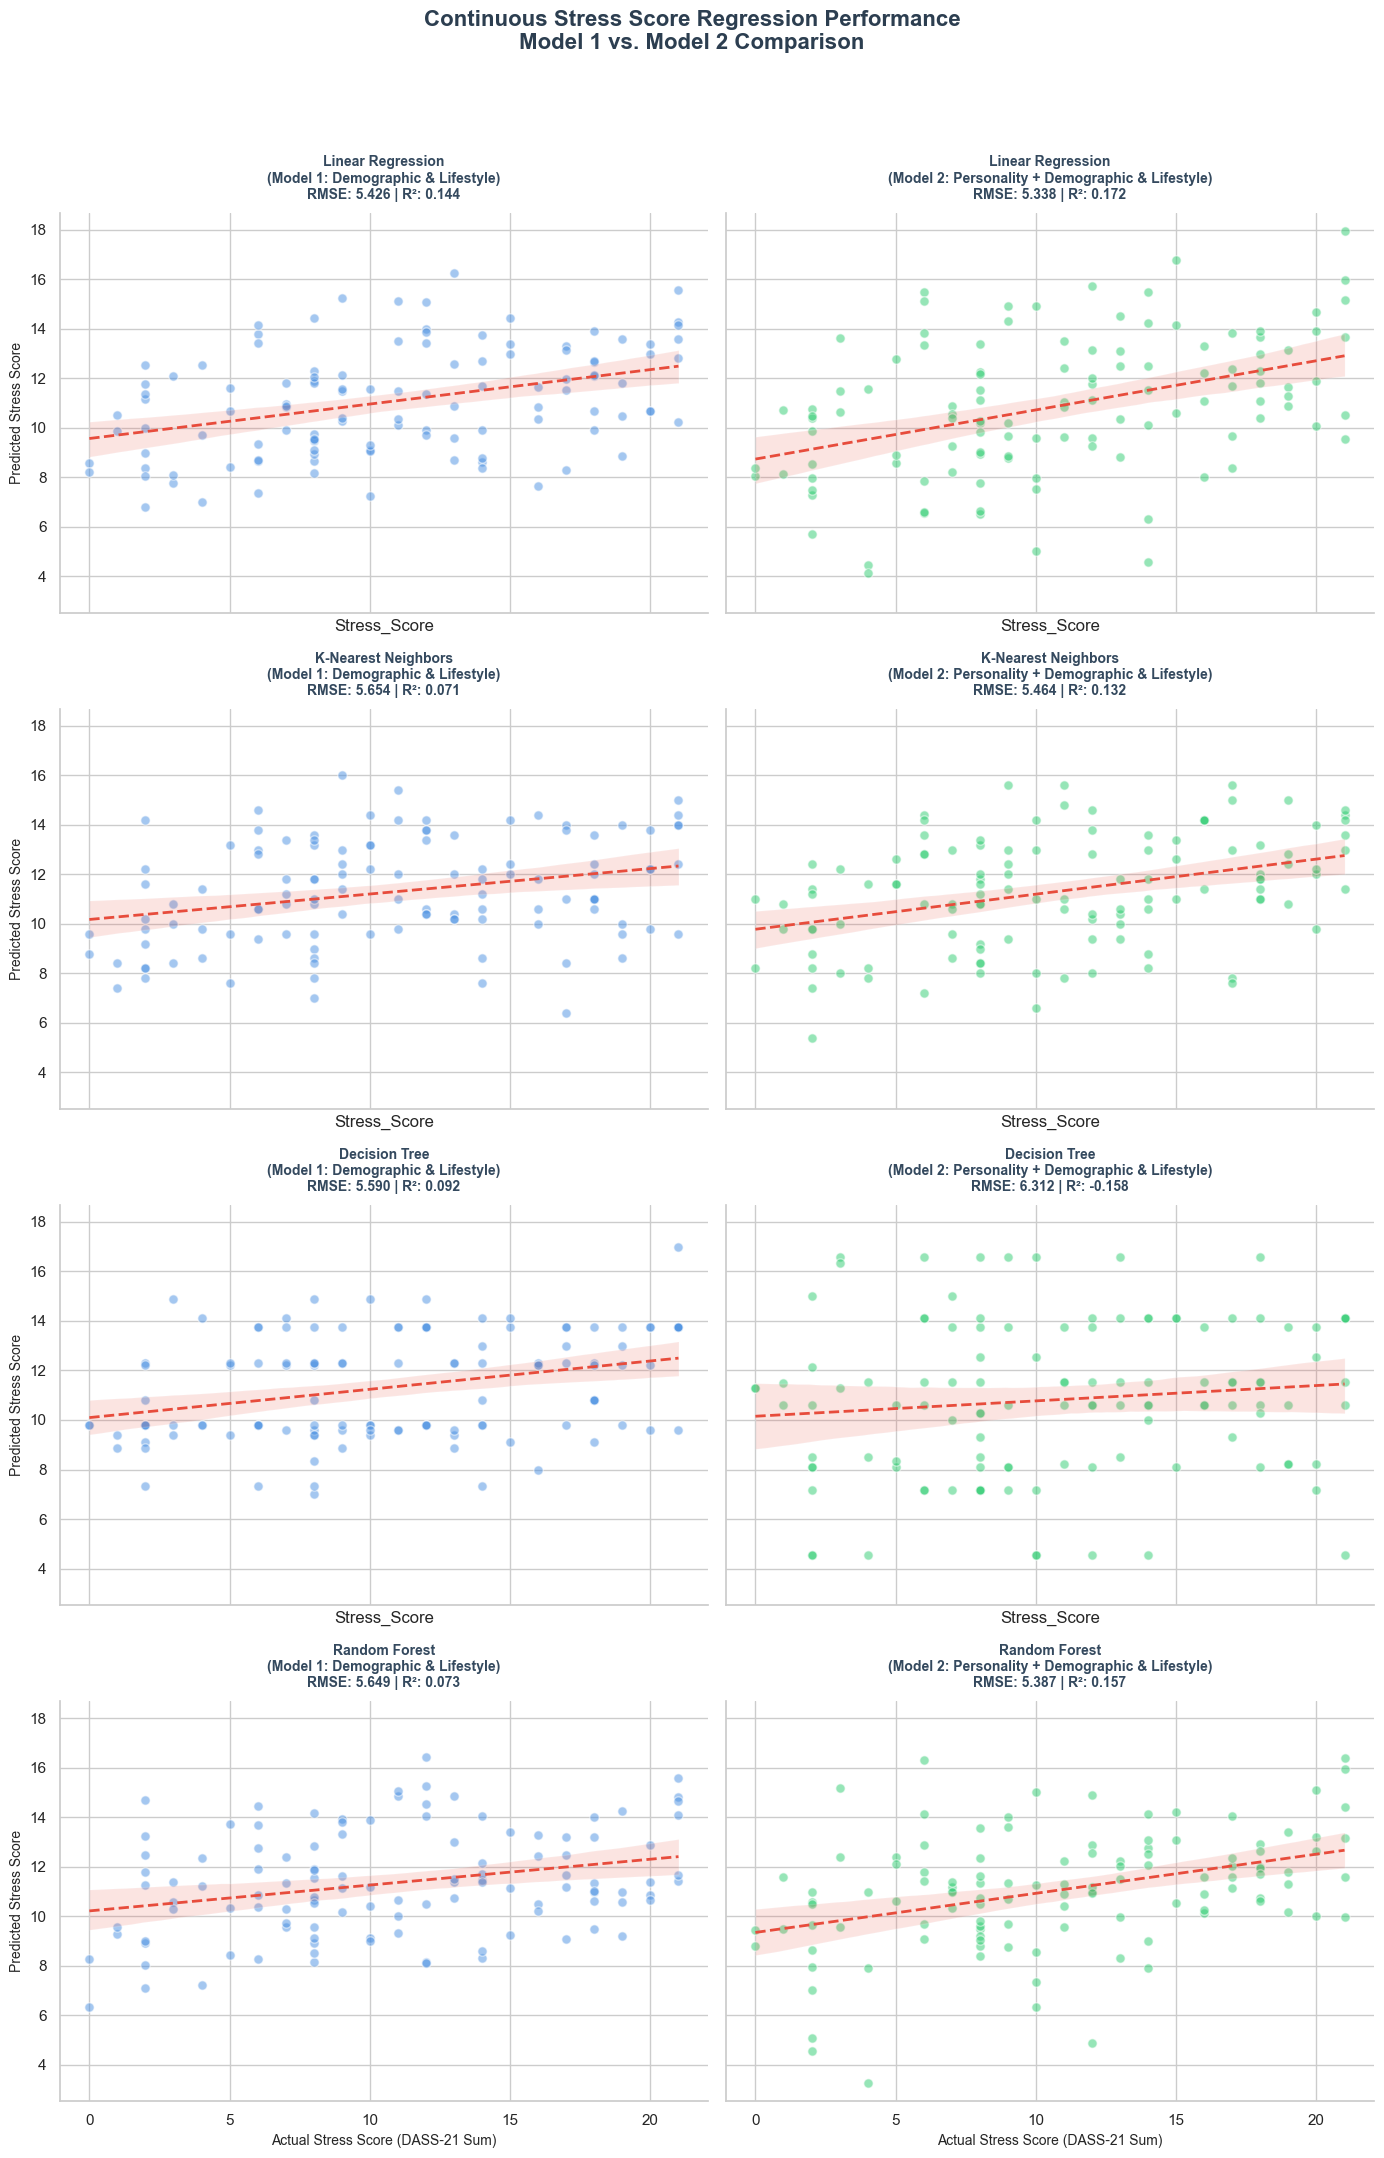

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

#NUMERICAL REGRESSION
ml_df = df[big_five_cols + ['Stress_Score', 'class_level_num', 'Program_Cleaned', 'Institution_Cleaned', 'Your gender'] + lifestyle_num_cols].copy()

categorical_features = ['Program_Cleaned', 'Institution_Cleaned', 'Your gender']
ml_df_encoded = pd.get_dummies(ml_df, columns=categorical_features, drop_first=True)

demo_lifestyle_features = [col for col in ml_df_encoded.columns if col not in big_five_cols + ['Stress_Score']]
all_regression_features = demo_lifestyle_features + big_five_cols
y_reg = ml_df_encoded['Stress_Score']

X1_train, X1_test, y_train, y_test = train_test_split(ml_df_encoded[demo_lifestyle_features], y_reg, test_size=0.2, random_state=42)
X2_train, X2_test, _, _ = train_test_split(ml_df_encoded[all_regression_features], y_reg, test_size=0.2, random_state=42)

scaler1 = StandardScaler()
X1_train_scaled = scaler1.fit_transform(X1_train)
X1_test_scaled = scaler1.transform(X1_test)

scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

reg_models = {
    "Linear Regression": LinearRegression(),
    "K-Nearest Neighbors": KNeighborsRegressor(n_neighbors=5),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

print("=== NUMERICAL REGRESSION METRICS ===")
predictions = {}
for name, model in reg_models.items():
    #Model 1
    model.fit(X1_train_scaled, y_train)
    p1 = model.predict(X1_test_scaled)
    mse1 = mean_squared_error(y_test, p1)
    rmse1 = np.sqrt(mse1)
    mae1 = mean_absolute_error(y_test, p1)
    r2_1 = r2_score(y_test, p1)

    #Model 2
    model.fit(X2_train_scaled, y_train)
    p2 = model.predict(X2_test_scaled)
    mse2 = mean_squared_error(y_test, p2)
    rmse2 = np.sqrt(mse2)
    mae2 = mean_absolute_error(y_test, p2)
    r2_2 = r2_score(y_test, p2)

    predictions[name] = {"Base": p1, "With_TIPI": p2, "rmse1": rmse1, "r2_1": r2_1, "rmse2": rmse2, "r2_2": r2_2}
    print(f"\n{name:19} -> Model 1 (Baseline) | MSE: {mse1:.3f} | RMSE: {rmse1:.3f} | MAE: {mae1:.3f} | R²: {r2_1:.3f}")
    print(f"{' '*22}Model 2 (With TIPI) | MSE: {mse2:.3f} | RMSE: {rmse2:.3f} | MAE: {mae2:.3f} | R²: {r2_2:.3f}")

fig, axes = plt.subplots(4, 2, figsize=(14, 22), sharex=True, sharey=True)
fig.suptitle("Continuous Stress Score Regression Performance\nModel 1 vs. Model 2 Comparison", fontsize=16, weight="bold", color="#2c3e50", y=0.98)
for idx, name in enumerate(reg_models.keys()):
    sns.regplot(x=y_test, y=predictions[name]["Base"], ax=axes[idx, 0],
                scatter_kws={'alpha': 0.5, 'color': '#4A90E2', 's': 45, 'edgecolor': 'w'},
                line_kws={'color': '#E74C3C', 'linestyle': '--', 'linewidth': 2})
    axes[idx, 0].set_title(f"{name}\n(Model 1: Demographic & Lifestyle)\nRMSE: {predictions[name]['rmse1']:.3f} | R²: {predictions[name]['r2_1']:.3f}", fontsize=10, pad=10, weight='semibold', color='#34495e')
    axes[idx, 0].set_ylabel("Predicted Stress Score", fontsize=10)
    axes[idx, 0].spines['top'].set_visible(False); axes[idx, 0].spines['right'].set_visible(False)

    sns.regplot(x=y_test, y=predictions[name]["With_TIPI"], ax=axes[idx, 1],
                scatter_kws={'alpha': 0.5, 'color': '#2ECC71', 's': 45, 'edgecolor': 'w'},
                line_kws={'color': '#E74C3C', 'linestyle': '--', 'linewidth': 2})
    axes[idx, 1].set_title(f"{name}\n(Model 2: Personality + Demographic & Lifestyle)\nRMSE: {predictions[name]['rmse2']:.3f} | R²: {predictions[name]['r2_2']:.3f}", fontsize=10, pad=10, weight='semibold', color='#34495e')
    axes[idx, 1].spines['top'].set_visible(False); axes[idx, 1].spines['right'].set_visible(False)

    if idx == 3:
        axes[idx, 0].set_xlabel("Actual Stress Score (DASS-21 Sum)", fontsize=10)
        axes[idx, 1].set_xlabel("Actual Stress Score (DASS-21 Sum)", fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


=== CATEGORICAL CLASSIFICATION ACCURACIES ===
Logistic Regression   -> Model 1 Accuracy: 30.43% | Model 2 Accuracy: 28.70%
K-Nearest Neighbors   -> Model 1 Accuracy: 26.96% | Model 2 Accuracy: 25.22%
Decision Tree         -> Model 1 Accuracy: 21.74% | Model 2 Accuracy: 25.22%
Random Forest         -> Model 1 Accuracy: 28.70% | Model 2 Accuracy: 34.78%


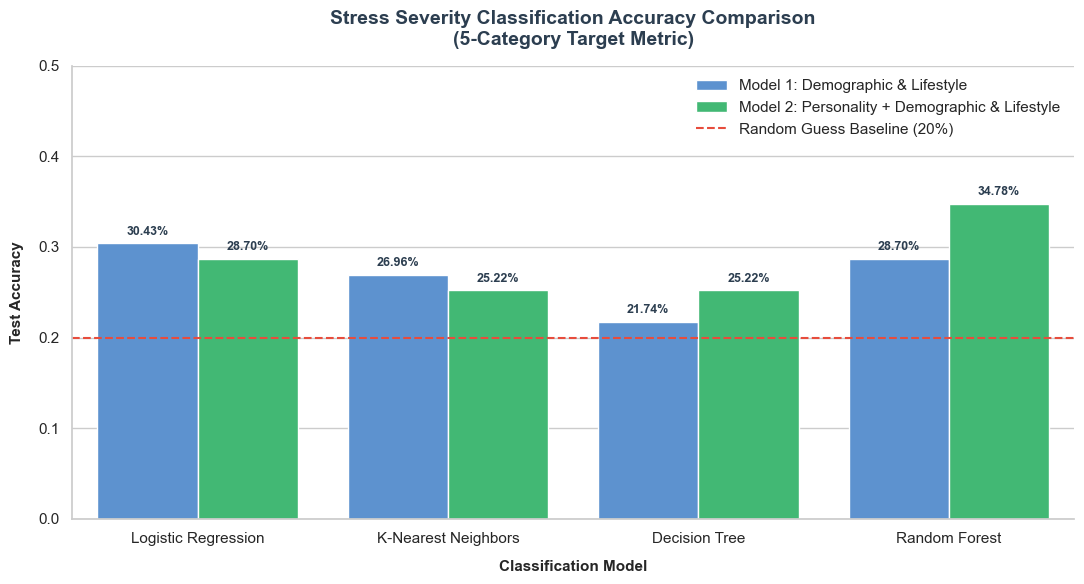

In [64]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

#Categorical Models
class_df = df[big_five_cols + ['Stress_Severity', 'Program_Cleaned', 'Institution_Cleaned']].copy()

class_df['class_level_cat'] = df['Your current class level is']

categorical_demo_lifestyle = ['Your gender'] + lifestyle_raw_cols
for col in categorical_demo_lifestyle:
    class_df[col] = df[col].apply(clean_text)

cat_features_classification = ['Program_Cleaned', 'Institution_Cleaned', 'class_level_cat'] + categorical_demo_lifestyle
class_df_encoded = pd.get_dummies(class_df, columns=cat_features_classification, drop_first=True)

base_class_cols = [col for col in class_df_encoded.columns if col not in big_five_cols + ['Stress_Severity']]
all_class_cols = base_class_cols + big_five_cols
y_class = class_df_encoded['Stress_Severity']

X1_c_train, X1_c_test, y_c_train, y_c_test = train_test_split(class_df_encoded[base_class_cols], y_class, test_size=0.2, random_state=42, stratify=y_class)
X2_c_train, X2_c_test, _, _ = train_test_split(class_df_encoded[all_class_cols], y_class, test_size=0.2, random_state=42, stratify=y_class)

scaler1_c = StandardScaler()
X1_c_train_scaled = scaler1_c.fit_transform(X1_c_train)
X1_c_test_scaled = scaler1_c.transform(X1_c_test)

scaler2_c = StandardScaler()
X2_c_train_scaled = scaler2_c.fit_transform(X2_c_train)
X2_c_test_scaled = scaler2_c.transform(X2_c_test)

class_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results_1 = []
results_2 = []
print("\n=== CATEGORICAL CLASSIFICATION ACCURACIES ===")
for name, model in class_models.items():
    model.fit(X1_c_train_scaled, y_c_train)
    acc1 = accuracy_score(y_c_test, model.predict(X1_c_test_scaled))
    results_1.append({"Model": name, "Accuracy": acc1, "Setup": "Model 1: Demographic & Lifestyle"})

    model.fit(X2_c_train_scaled, y_c_train)
    acc2 = accuracy_score(y_c_test, model.predict(X2_c_test_scaled))
    results_2.append({"Model": name, "Accuracy": acc2, "Setup": "Model 2: Personality + Demographic & Lifestyle"})
    print(f"{name:21} -> Model 1 Accuracy: {acc1*100:.2f}% | Model 2 Accuracy: {acc2*100:.2f}%")

combined_class_results = pd.concat([pd.DataFrame(results_1), pd.DataFrame(results_2)], ignore_index=True)
plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x='Model', y='Accuracy', hue='Setup', data=combined_class_results, palette=['#4A90E2', '#2ECC71'])
plt.title('Stress Severity Classification Accuracy Comparison\n(5-Category Target Metric)', fontsize=14, weight='bold', pad=15, color='#2c3e50')
plt.xlabel('Classification Model', fontsize=11, labelpad=10, weight='semibold')
plt.ylabel('Test Accuracy', fontsize=11, labelpad=10, weight='semibold')
plt.ylim(0, 0.50)
plt.axhline(0.20, color='#E74C3C', linestyle='--', linewidth=1.5, label='Random Guess Baseline (20%)')

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height*100:.2f}%', (p.get_x() + p.get_width() / 2., height + 0.008),
                    ha='center', va='center', fontsize=9, color='#2c3e50', weight='bold', xytext=(0, 3), textcoords='offset points')
plt.legend(frameon=True, facecolor='white', edgecolor='none')
sns.despine()
plt.tight_layout()
plt.show()

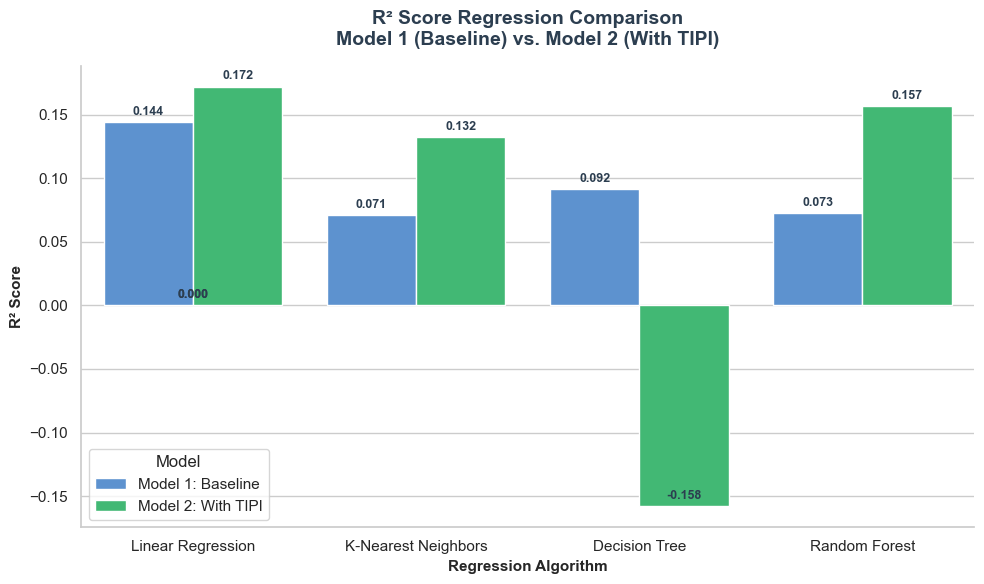

In [65]:
#R squared regression comparision
r2_results = []
for name in reg_models.keys():
    r2_results.append({"Algorithm": name, "R² Score": predictions[name]["r2_1"], "Model": "Model 1: Baseline"})
    r2_results.append({"Algorithm": name, "R² Score": predictions[name]["r2_2"], "Model": "Model 2: With TIPI"})

r2_df = pd.DataFrame(r2_results)

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
ax1 = sns.barplot(x="Algorithm", y="R² Score", hue="Model", data=r2_df, palette=["#4A90E2", "#2ECC71"])
plt.title("R² Score Regression Comparison\nModel 1 (Baseline) vs. Model 2 (With TIPI)", fontsize=14, weight="bold", pad=15, color="#2c3e50")
plt.xlabel("Regression Algorithm", fontsize=11, weight="semibold")
plt.ylabel("R² Score", fontsize=11, weight="semibold")

for p in ax1.patches:
    height = p.get_height()
    ax1.annotate(f"{height:.3f}", (p.get_x() + p.get_width() / 2., height),
                ha="center", va="bottom", fontsize=9, color="#2c3e50", weight="bold", xytext=(0, 3), textcoords="offset points")

sns.despine()
plt.tight_layout()
plt.show()

HIERARCHICAL REGRESSION: does personality add beyond demographic & lifestyle factors?


,Model,R²,Adj. R²,RMSE,ΔR²,F change,p
0,Step 1: Demographic & Lifestyle,0.186,0.125,4.710,,,
1,Step 2: + Big Five personality traits,0.281,0.220,4.426,0.095,"F(5, 525) = 13.86",< .001



SPEARMAN CORRELATIONS: Big Five traits ranked by strength of associationwith Stress


,Trait,Spearman rho,p
0,Emotional_Stability,-0.368,< .001
1,Agreeableness,-0.102,.014
2,Conscientiousness,-0.058,.169
3,Extraversion,-0.028,.507
4,Openness,0.005,.907


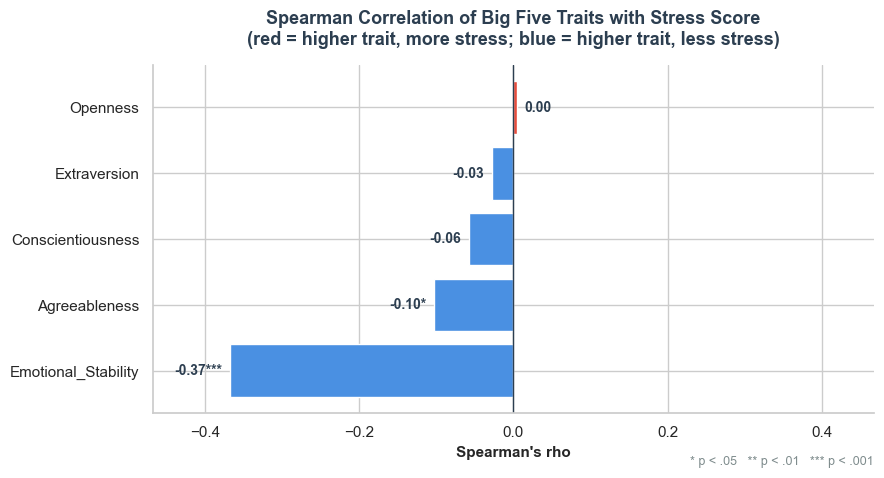

In [66]:
#Spearman Correlations
from scipy.stats import spearmanr
import statsmodels.api as sm  

def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''

def format_p(p):
    """APA-style p-value: '< .001' for very small values, otherwise 3 decimals without the leading zero."""
    if p < 0.001:
        return "< .001"
    return f"{p:.3f}".lstrip("0")

def standardise(X):
    X = X.astype(float)
    X = X.loc[:, X.std() > 0]                 
    return (X - X.mean()) / X.std()


y_full = ml_df_encoded['Stress_Score']
X_step1 = standardise(ml_df_encoded[demo_lifestyle_features])
X_step2 = standardise(ml_df_encoded[all_regression_features])

step1 = sm.OLS(y_full, sm.add_constant(X_step1)).fit()
step2 = sm.OLS(y_full, sm.add_constant(X_step2)).fit()

rmse1 = np.sqrt(np.mean(step1.resid ** 2))
rmse2 = np.sqrt(np.mean(step2.resid ** 2))
f_stat, p_change, df_diff = step2.compare_f_test(step1)

hier_table = pd.DataFrame({
    'Model': ['Step 1: Demographic & Lifestyle', 'Step 2: + Big Five personality traits'],
    'R²': [step1.rsquared, step2.rsquared],
    'Adj. R²': [step1.rsquared_adj, step2.rsquared_adj],
    'RMSE': [rmse1, rmse2],
    'ΔR²': ['', f"{step2.rsquared - step1.rsquared:.3f}"],
    'F change': ['', f"F({int(df_diff)}, {int(step2.df_resid)}) = {f_stat:.2f}"],
    'p': ['', format_p(p_change)],
}).round(3)

print("HIERARCHICAL REGRESSION: does personality add beyond demographic & lifestyle factors?")
display(hier_table)

rows = []
for trait in big_five_cols:
    rho, p = spearmanr(df[trait], df['Stress_Score'])
    rows.append({'Trait': trait, 'Spearman rho': rho, 'p_raw': p})

spearman_df = pd.DataFrame(rows)
spearman_df = spearman_df.reindex(spearman_df['Spearman rho'].abs().sort_values(ascending=False).index).reset_index(drop=True)

spearman_display = spearman_df[['Trait', 'Spearman rho']].round(3)
spearman_display['p'] = spearman_df['p_raw'].apply(format_p)
print("\nSPEARMAN CORRELATIONS: Big Five traits ranked by strength of associationwith Stress")
display(spearman_display)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = spearman_df.sort_values('Spearman rho')
colors = ['#E74C3C' if r > 0 else '#4A90E2' for r in plot_df['Spearman rho']]
bars = ax.barh(plot_df['Trait'], plot_df['Spearman rho'], color=colors)
ax.axvline(0, color='#2c3e50', linewidth=1)
for bar, r, p in zip(bars, plot_df['Spearman rho'], plot_df['p_raw']):
    x = bar.get_width()
    ax.text(x + (0.01 if x >= 0 else -0.01), bar.get_y() + bar.get_height() / 2,
            f"{r:.2f}{stars(p)}", va='center', ha='left' if x >= 0 else 'right',
            fontsize=10, weight='bold', color='#2c3e50')
lim = max(0.1, plot_df['Spearman rho'].abs().max() + 0.1)
ax.set_xlim(-lim, lim)
ax.set_title("Spearman Correlation of Big Five Traits with Stress Score\n(red = higher trait, more stress; blue = higher trait, less stress)",
             fontsize=13, weight='bold', pad=15, color='#2c3e50')
ax.set_xlabel("Spearman's rho", fontsize=11, weight='semibold')
ax.set_ylabel("")
ax.text(1, -0.15, "* p < .05   ** p < .01   *** p < .001", transform=ax.transAxes, ha='right', fontsize=9, color='#7f8c8d')
sns.despine()
plt.tight_layout()
plt.show()